# Phase 4 — MiniLM fine-tuning (validation only)
Viewer over `artifacts/reports/finetune_*_report.json` and each run's `train_log_history.json`.
Validation numbers come from the Sentence-Transformers `InformationRetrievalEvaluator` (same evaluator for epoch 0 and every epoch);
Phase 5 re-scores every model with the project's own metric code. `test.tsv` is not used.

In [1]:
import sys
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "base.yaml").is_file())
sys.path.insert(0, str(root))
from src.config import load_config
from src.utils import read_json
cfg = load_config(["configs/baseline.yaml", "configs/finetune.yaml"], root=root)
reports = cfg["_abs"]["reports_dir"]
REP = {}
for key, e in cfg["experiments"].items():
    p = reports / f"finetune_{e['run_id']}_report.json"
    if p.is_file(): REP[key] = read_json(p)
    print(f"{key:>14} ({e['run_id']}):", REP[key]["status"] if key in REP else "NOT RUN YET (python scripts/finetune.py --experiment %s)" % key)
vp = reports / "finetune_verification.json"
print("verification:", read_json(vp)["status"] if vp.is_file() else "not run")

 positive_only (ft_pos_only): PASS
 hard_negative (ft_hardneg_dense): PASS
verification: PASS


## 1. Configuration shared by both runs

In [2]:
if REP: display(pd.Series(next(iter(REP.values()))["hyperparameters"], name="value").to_frame())

,value
batch_sampler,no_duplicates
batch_size,8
epochs,2
learning_rate,0.00002
loss,MultipleNegativesRankingLoss
max_seq_length,256
steps_per_epoch,93
total_steps,186
warmup_ratio,0.1
warmup_steps,19


## 2. Validation metrics by stage (evaluator-defined; epoch 0 = pretrained, same evaluator)

In [3]:
rows = []
for k, r in REP.items():
    for stage, m in r["validation"]["by_stage"].items():
        rows.append({"run": r["run_id"], "stage": stage, **{n.replace("val_cosine_", ""): v for n, v in m.items()}})
if rows:
    df = pd.DataFrame(rows); display(df.round(4))

,run,stage,accuracy@1,accuracy@10,accuracy@5,map@10,mrr@10,ndcg@10,precision@1,precision@10,precision@5,recall@1,recall@10,recall@5
0,ft_pos_only,epoch_1,0.5370,0.8395,0.7840,0.6401,0.6486,0.6910,0.5370,0.0901,0.1667,0.5175,0.8364,0.7757
1,ft_pos_only,epoch_2,0.5556,0.8395,0.8086,0.6481,0.6584,0.6974,0.5556,0.0901,0.1704,0.5360,0.8364,0.7973
2,ft_pos_only,pre_training,0.5556,0.8025,0.7778,0.6398,0.6536,0.6816,0.5556,0.0852,0.1630,0.5329,0.7932,0.7634
3,ft_hardneg_dense,epoch_1,0.6049,0.8395,0.8025,0.6838,0.6915,0.7229,0.6049,0.0901,0.1716,0.5813,0.8333,0.7963
4,ft_hardneg_dense,epoch_2,0.6420,0.8457,0.8148,0.7110,0.7174,0.7433,0.6420,0.0901,0.1741,0.6183,0.8323,0.8117
5,ft_hardneg_dense,pre_training,0.5556,0.8025,0.7778,0.6398,0.6536,0.6816,0.5556,0.0852,0.1630,0.5329,0.7932,0.7634


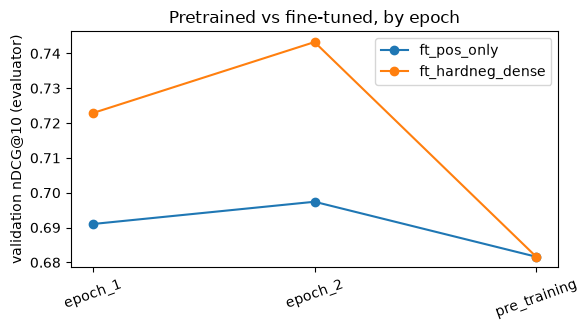

In [4]:
if REP:
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for k, r in REP.items():
        pm = r["validation"]["primary_metric"]
        stages = list(r["validation"]["by_stage"])
        ax.plot(range(len(stages)), [r["validation"]["by_stage"][s][pm] for s in stages], marker="o", label=r["run_id"])
        ax.set_xticks(range(len(stages))); ax.set_xticklabels(stages, rotation=20)
    ax.set(ylabel="validation nDCG@10 (evaluator)", title="Pretrained vs fine-tuned, by epoch"); ax.legend(); plt.tight_layout(); plt.show()

## 3. Change vs pretrained (negative values are valid results)

In [5]:
if REP:
    display(pd.DataFrame({r["run_id"]: {"best_stage": r["validation"]["best_stage"], "pretrained": r["validation"]["pre_training_primary"],
        "best": r["validation"]["best_primary"], "abs_change": r["validation"]["abs_change_primary"],
        "rel_change_%": r["validation"]["rel_change_primary_pct"]} for r in REP.values()}))

,ft_pos_only,ft_hardneg_dense
best_stage,epoch_2,epoch_2
pretrained,0.681618,0.681618
best,0.697414,0.743264
abs_change,0.015796,0.061646
rel_change_%,2.317466,9.044056


## 4. Training loss, runtime and memory

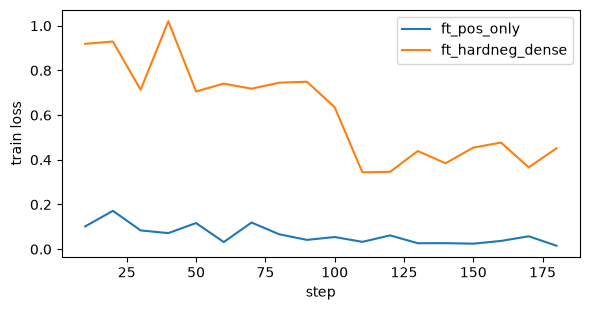

,ft_pos_only,ft_hardneg_dense
global_step,186,186
train_wall,974.2,1271.8
trainer_reported_train_runtime,965.3564,1264.8234
note,sampled every 2s; not a precise profile,sampled every 2s; not a precise profile
peak_rss_observed,1608.9,2254.2


In [6]:
import json
if REP:
    fig, ax = plt.subplots(figsize=(6, 3.2))
    for k, r in REP.items():
        hist = read_json(root / "artifacts" / "models" / r["run_id"] / "train_log_history.json")
        pts = [(h["step"], h["loss"]) for h in hist if "loss" in h and "step" in h]
        if pts: ax.plot(*zip(*pts), label=r["run_id"])
    ax.set(xlabel="step", ylabel="train loss"); ax.legend(); plt.tight_layout(); plt.show()
    display(pd.DataFrame({r["run_id"]: {**r["timing_s"], **r["memory_mb"]} for r in REP.values()}))

## 5. Exit gates

In [7]:
if REP: display(pd.DataFrame({r["run_id"]: r["gates"] for r in REP.values()}))

,ft_pos_only,ft_hardneg_dense
data:negative_never_a_known_positive,True,True
data:no_duplicate_rows,True,True
data:no_validation_or_test_queries,True,True
data:pairs_are_judged_train_positives,True,True
data:queries_are_training_queries_only,True,True
embedding_dim_preserved,True,True
max_seq_length_preserved,True,True
model_saved,True,True
reloaded_equals_in_memory,True,True
reloaded_model_embeds_finite_correct_shape,True,True


## 6. Caveats
- Selecting the best epoch inside a run uses validation; the final model between runs is chosen in Phase 5 on validation, then tested once.
- Mined negatives are unjudged; a worse hard-negative run is a legitimate outcome (false negatives).
- CPU training is only approximately reproducible across library versions.